In [25]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Try importing LightGBM, fallback to HistGradientBoostingClassifier if not installed
try:
    from lightgbm import LGBMClassifier
    has_lgbm = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    has_lgbm = False

import warnings
warnings.filterwarnings('ignore')

print("All modeling libraries imported successfully.")
print(f"Ensemble engine: {'LightGBM' if has_lgbm else 'HistGradientBoostingClassifier'}")

All modeling libraries imported successfully.
Ensemble engine: HistGradientBoostingClassifier


In [26]:
# Load the raw dataset
df = pd.read_csv('train.csv')

print(f"Data loaded successfully. Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(3)

Data loaded successfully. Shape: 384,873 rows, 14 columns


,id,orderDate,deliveryDate,itemID,size,color,manufacturerID,price,customerID,salutation,dateOfBirth,state,creationDate,returnShipment
0,1,2012-10-10,2012-11-05,2244,m,grey,33,59.9,2367,Mrs,1943-10-14,Baden-Wuerttemberg,2012-04-03,0
1,2,2013-03-15,NaN,2806,37,stained,1,189.9,82758,Mrs,1967-08-07,Bavaria,2013-03-15,0
2,3,2012-04-23,2012-05-03,263,m,ocher,5,69.9,12488,Mrs,1980-12-22,Hesse,2012-04-23,1


In [27]:
# 1. Parse dates
df['orderDate'] = pd.to_datetime(df['orderDate'], errors='coerce')
df['deliveryDate'] = pd.to_datetime(df['deliveryDate'], errors='coerce')
df['dateOfBirth'] = pd.to_datetime(df['dateOfBirth'], errors='coerce')
df['creationDate'] = pd.to_datetime(df['creationDate'], errors='coerce')

# 2. Date-based engineered features
df['delivery_duration'] = (df['deliveryDate'] - df['orderDate']).dt.days
df['is_delivery_missing'] = df['deliveryDate'].isna().astype(int)
df['customer_age'] = df['orderDate'].dt.year - df['dateOfBirth'].dt.year
df['account_age_days'] = (df['orderDate'] - df['creationDate']).dt.days
df['order_month'] = df['orderDate'].dt.month
df['order_day_of_week'] = df['orderDate'].dt.day_name()

# 3. Behavioral features (moved up from Cell 14)
same_item_sizes = df.groupby(['customerID', 'orderDate', 'itemID'])['size'].transform('nunique')
df['is_bracketed'] = (same_item_sizes > 1).astype(int)
df['is_unsized'] = df['size'].astype(str).str.lower().str.contains('unsized').astype(int)

print("All features engineered successfully.")

All features engineered successfully.


In [28]:
# Select the feature columns your preprocessor expects
feature_cols = [
    'size', 'color', 'manufacturerID', 'price', 
    'salutation', 'state', 'delivery_duration'
]

# (Add 'customer_age', 'account_age_days', 'is_bracketed' if your preprocessor uses them)

X = df[feature_cols]
y = df['returnShipment']

# Re-split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Updated X_train columns:", list(X_train.columns))

Updated X_train columns: ['size', 'color', 'manufacturerID', 'price', 'salutation', 'state', 'delivery_duration']


In [29]:

# Define features to exclude from model input
cols_to_drop = [
    'id', 'customerID', 'itemID', 'orderDate', 'deliveryDate', 
    'dateOfBirth', 'creationDate', 'returnShipment', 'color', 'size'
]

X = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
y = df['returnShipment']

# Explicit numerical and categorical column definitions
numeric_features = [
    'price', 'manufacturerID', 'delivery_duration', 
    'is_delivery_missing', 'customer_age', 'account_age_days', 
    'order_month', 'is_bracketed', 'is_unsized'
]

categorical_features = ['salutation', 'state', 'order_day_of_week']

# 80/20 Stratified Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Numeric pipeline: median imputation + standard scaling
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: most frequent imputation + one-hot encoding
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Full preprocessor ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print(f"X_train samples: {X_train.shape[0]:,} | X_val samples: {X_val.shape[0]:,}")
print("Pre-processing pipeline defined.")

X_train samples: 307,898 | X_val samples: 76,975
Pre-processing pipeline defined.


In [30]:
# Define feature sets
# Drop raw identifier columns and raw date strings that are not suitable for direct tabular modeling
features_to_drop = [
    'id', 'customerID', 'itemID', 'orderDate', 
    'deliveryDate', 'dateOfBirth', 'creationDate', 
    'returnShipment', 'price_tier'
]

# Separate features (X) and target (y)
X = df.drop(columns=[col for col in features_to_drop if col in df.columns])
y = df['returnShipment']

print(f"Features matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")
print(f"Selected Features: {list(X.columns)}")

# Stratified split to preserve class balance (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTrain set: {X_train.shape[0]:,} samples")
print(f"Validation set: {X_val.shape[0]:,} samples")
print(f"Train target balance: {y_train.mean():.4f}")
print(f"Validation target balance: {y_val.mean():.4f}")

Features matrix shape: (384873, 14)
Target vector shape: (384873,)
Selected Features: ['size', 'color', 'manufacturerID', 'price', 'salutation', 'state', 'delivery_duration', 'is_delivery_missing', 'customer_age', 'account_age_days', 'order_month', 'order_day_of_week', 'is_bracketed', 'is_unsized']

Train set: 307,898 samples
Validation set: 76,975 samples
Train target balance: 0.4828
Validation target balance: 0.4828


In [31]:
# Define numeric and categorical feature groups
numeric_features = [
    'price', 
    'manufacturerID', 
    'delivery_duration', 
    'is_delivery_missing', 
    'customer_age', 
    'account_age_days', 
    'order_month'
]

categorical_features = [
    'salutation', 
    'state', 
    'order_day_of_week'
]

# Preprocessing pipeline for numeric attributes:
# Impute missing values with median, followed by standard feature scaling
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing pipeline for categorical attributes:
# Impute missing values with most frequent value, then one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine into a unified preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'  # ignores high-cardinality size/color for baseline stability
)

print("Preprocessor configured successfully:")
print(preprocessor)

Preprocessor configured successfully:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['price', 'manufacturerID',
                                  'delivery_duration', 'is_delivery_missing',
                                  'customer_age', 'account_age_days',
                                  'order_month']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
    

In [32]:
print("delivery_duration in X_train?", 'delivery_duration' in X_train.columns)
print("\nAll X_train columns:")
print(list(X_train.columns))

delivery_duration in X_train? True

All X_train columns:
['size', 'color', 'manufacturerID', 'price', 'salutation', 'state', 'delivery_duration', 'is_delivery_missing', 'customer_age', 'account_age_days', 'order_month', 'order_day_of_week', 'is_bracketed', 'is_unsized']


In [33]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=500, random_state=42))
])

print("Training Logistic Regression...")
lr_pipeline.fit(X_train, y_train)

# Evaluation
y_pred_lr = lr_pipeline.predict(X_val)
y_prob_lr = lr_pipeline.predict_proba(X_val)[:, 1]

print("\n--- Logistic Regression Validation Report ---")
print(classification_report(y_val, y_pred_lr, digits=4))
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob_lr):.4f}")

Training Logistic Regression...

--- Logistic Regression Validation Report ---
              precision    recall  f1-score   support

           0     0.6470    0.5872    0.6157     39813
           1     0.5976    0.6568    0.6258     37162

    accuracy                         0.6208     76975
   macro avg     0.6223    0.6220    0.6207     76975
weighted avg     0.6232    0.6208    0.6206     76975

ROC-AUC: 0.6718


In [34]:
if has_lgbm:
    model_clf = LGBMClassifier(n_estimators=200, learning_rate=0.08, random_state=42)
    model_label = "LightGBM"
else:
    model_clf = HistGradientBoostingClassifier(max_iter=200, random_state=42)
    model_label = "HistGradientBoosting"

tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', model_clf)
])

print(f"Training {model_label} Classifier...")
tree_pipeline.fit(X_train, y_train)

# Evaluation
y_pred_tree = tree_pipeline.predict(X_val)
y_prob_tree = tree_pipeline.predict_proba(X_val)[:, 1]

print(f"\n--- {model_label} Validation Report ---")
print(classification_report(y_val, y_pred_tree, digits=4))
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob_tree):.4f}")

Training HistGradientBoosting Classifier...

--- HistGradientBoosting Validation Report ---
              precision    recall  f1-score   support

           0     0.7038    0.5382    0.6100     39813
           1     0.6049    0.7573    0.6726     37162

    accuracy                         0.6440     76975
   macro avg     0.6543    0.6478    0.6413     76975
weighted avg     0.6561    0.6440    0.6402     76975

ROC-AUC: 0.7053


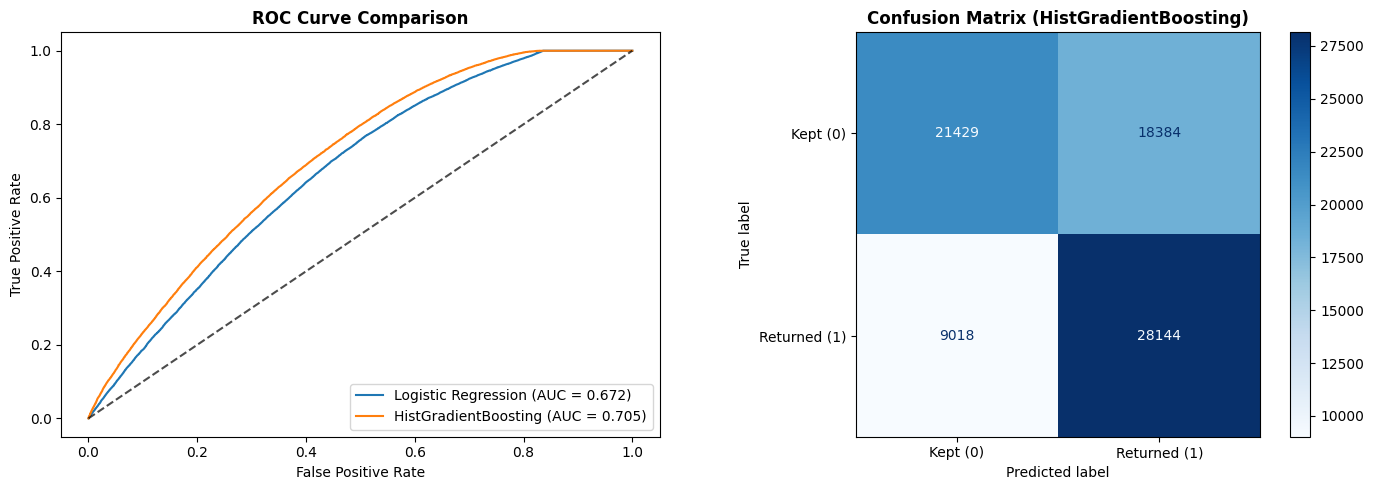

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curves Comparison
fpr_lr, tpr_lr, _ = roc_curve(y_val, y_prob_lr)
fpr_tree, tpr_tree, _ = roc_curve(y_val, y_prob_tree)

axes[0].plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_val, y_prob_lr):.3f})")
axes[0].plot(fpr_tree, tpr_tree, label=f"{model_label} (AUC = {roc_auc_score(y_val, y_prob_tree):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.7)
axes[0].set_title('ROC Curve Comparison', fontsize=12, weight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

# Confusion Matrix for Best Model
cm = confusion_matrix(y_val, y_pred_tree)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Kept (0)', 'Returned (1)'])
disp.plot(cmap='Blues', ax=axes[1], values_format='d')
axes[1].set_title(f'Confusion Matrix ({model_label})', fontsize=12, weight='bold')

plt.tight_layout()
plt.show()

In [36]:
# Define features to exclude from model input
cols_to_drop = [
    'id', 'customerID', 'itemID', 'orderDate', 'deliveryDate', 
    'dateOfBirth', 'creationDate', 'returnShipment', 'color', 'size'
]

X = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
y = df['returnShipment']

# Explicit numerical and categorical column definitions
numeric_features = [
    'price', 'manufacturerID', 'delivery_duration', 
    'is_delivery_missing', 'customer_age', 'account_age_days', 
    'order_month', 'is_bracketed', 'is_unsized'
]

categorical_features = ['salutation', 'state', 'order_day_of_week']

# 80/20 Stratified Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Numeric pipeline: median imputation + standard scaling
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: most frequent imputation + one-hot encoding
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Full preprocessor ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print(f"X_train samples: {X_train.shape[0]:,} | X_val samples: {X_val.shape[0]:,}")
print("Pre-processing pipeline defined.")

X_train samples: 307,898 | X_val samples: 76,975
Pre-processing pipeline defined.


In [37]:
# 1. Flag bracketing: customer ordering the same item in multiple sizes on the same date
same_item_sizes = df.groupby(['customerID', 'orderDate', 'itemID'])['size'].transform('nunique')
df['is_bracketed'] = (same_item_sizes > 1).astype(int)

# 2. Flag unsized items: accessories, bags, or non-fitted apparel
df['is_unsized'] = df['size'].str.lower().str.contains('unsized').astype(int)

print("Engineered behavioral features:")
print(f"Bracketed orders rate: {df['is_bracketed'].mean():.2%}")
print(f"Unsized products rate: {df['is_unsized'].mean():.2%}")

Engineered behavioral features:
Bracketed orders rate: 14.46%
Unsized products rate: 5.41%


In [38]:
# Define features to exclude from tabular modeling
cols_to_drop = [
    'id', 'customerID', 'itemID', 'orderDate', 'deliveryDate', 
    'dateOfBirth', 'creationDate', 'returnShipment', 'color', 'size'
]

if 'price_tier' in df.columns:
    cols_to_drop.append('price_tier')

X = df.drop(columns=[col for col in cols_to_drop if col in df.columns])
y = df['returnShipment']

# Explicit numerical and categorical columns
numeric_features = [
    'price', 'manufacturerID', 'delivery_duration', 
    'is_delivery_missing', 'customer_age', 'account_age_days', 
    'order_month', 'is_bracketed', 'is_unsized'
]

categorical_features = ['salutation', 'state', 'order_day_of_week']

# 80/20 Stratified Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Numeric pipeline: median imputation + standard scaling
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: mode imputation + one-hot encoding
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print(f"X_train shape: {X_train.shape} | X_val shape: {X_val.shape}")

X_train shape: (307898, 12) | X_val shape: (76975, 12)


In [39]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=500, random_state=42))
])

# Fit on training data
lr_pipeline.fit(X_train, y_train)

# Generate predictions and probabilities
y_pred_lr = lr_pipeline.predict(X_val)
y_prob_lr = lr_pipeline.predict_proba(X_val)[:, 1]

print("=== Logistic Regression Validation Report ===")
print(classification_report(y_val, y_pred_lr, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_val, y_prob_lr):.4f}")

=== Logistic Regression Validation Report ===
              precision    recall  f1-score   support

           0     0.6515    0.6278    0.6395     39813
           1     0.6162    0.6403    0.6280     37162

    accuracy                         0.6338     76975
   macro avg     0.6339    0.6341    0.6338     76975
weighted avg     0.6345    0.6338    0.6339     76975

ROC-AUC Score: 0.6973
